# Design Space Exploration of Stagnation Temperature Probes: Loss and Recovery Ratio of a Kiel Probe

__Ashley D. Scillitoe__, The Alan Turing Institute, London, U.K.

__Bryn Ubald__, University of Cambridge, Cambridge, U.K.

__Pranay Seshadri__, The Alan Turing Institute, London, U.K., and Imperial College London, London, U.K.

__Shahrokh Shahpar__, Rolls-Royce plc., Derby, U.K.

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

This notebook analyzes the CFD results that Scillitoe et al. [[1]][R1] published in the [equadratures/data-sets](https://github.com/equadratures/data-sets) repository (`probes`; the same arrays are in the authors' [probe-subspaces](https://github.com/ascillitoe/probe-subspaces) repository). The archive states no licence and is hosted here with credit (see `DATA.md`). Page, equation, table and figure numbers refer to the published conference paper (ASME Turbo Expo 2020, GT2020-16277, Vol. 2C, V02CT35A057), read from the ASME PDF. The notebook runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, in under a minute.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import convert_data as cd

SEED = 2020                        # the only seed in this notebook (all bootstrap replicates)
t_start = time.perf_counter()
m = 7
short = ['ellipse', 'hole fwd', 'hole angle', 'Kiel LE', 'Kiel outer', 'Kiel inner', 'hole dia']

### Summary

Scillitoe et al. [[1]][R1] morph a single-shrouded Kiel stagnation-temperature probe with seven geometric design parameters, run conjugate RANS simulations of 128 designs at six Mach numbers, and find ridge approximations by polynomial variable projection [[2]][R2]: a one-dimensional linear ridge for the stagnation pressure loss and a two-dimensional cubic ridge for the slope of the temperature recovery ratio with Mach number. From the published runs (values only, outputs standardized by the authors), the global quadratic active subspace estimator gives a loss direction that matches the paper's Eq. 12 (cosine 0.9996) once the archive's hole-angle column is given the paper's sign, and a two-dimensional recovery subspace that matches the paper's (principal-angle cosines 0.9972 and 0.9810). The loss is almost a linear function of one variable dominated by the Kiel outer diameter ($\lambda_1/\lambda_2 = 84.5$), while the recovery objective is a valley in the bleed-hole-diameter direction with a weaker second direction that thins the shroud ($\lambda_1/\lambda_2 = 8.2$, $\lambda_2/\lambda_3 = 6.94$).

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend. When only values of $f$ are available, $\nabla f$ is replaced by the gradient of a fitted model, here a global quadratic, and the estimate is assessed by bootstrap resampling and by comparison with other estimators. The paper's ridge approximations, $f(\mathbf x) \approx g(\mathbf U^T\mathbf x)$ with $\mathbf U$ and a polynomial $g$ fitted together, look for the same kind of structure by a different route. See Constantine [[4]][R4].

### The model

**Probe and solver** (Secs. 3, 3.1, 3.2, pp. 3–5). The geometry is a real single-shrouded Kiel temperature probe used in engine tests (Fig. 4): a thermocouple sheathed in Inconel 600, NiSil/NiCroSil wires insulated with MgO, a Kiel shroud with bleed holes, and a stainless steel support with alumina insulation. A quarter of the probe is meshed (symmetry planes in y and z) with a structured multi-block mesh of about 4 million nodes, solid regions included with conformal interfaces. The 128 meshes are made by morphing the baseline mesh with radial basis functions (Wendland C0 kernel), applying the seven deformations one after another; this took about 4,000 CPU hours. ANSYS Fluent solves the 3-D compressible RANS equations with the realizable $k$–$\varepsilon$ model (streamline-curvature and Kato–Launder stagnation corrections), fully coupled with conduction in the solids. Inflow turbulence intensity is 0.5 % and viscosity ratio 5; the outlet static pressure is 101,325 Pa; inlet and outlet lie 5D upstream and 25D downstream of the probe. Each design is run at the six Mach numbers of Table 2 (inlet stagnation pressure 107,850–154,459 Pa and temperature 305–338 K, chosen so the inlet static temperature stays 300 K): 768 simulations and about 20,000 CPU hours. There is no radiation, and the support is extended about 11D downstream instead of modelling the wires to the reference junction.

**Quantities of interest** (Sec. 2, pp. 2–3). The stagnation pressure loss coefficient is $Y_p = 100\,(P_{0,in} - P_{0,out})/(P_{0,in} - P_{out})$ in % (Eq. 1), with outlet values mass-averaged, and the loss objective is its mean over the Mach numbers $\mathcal M = \{0.3, 0.4, \dots, 0.8\}$:

$$O_{Y_p} = \frac16\sum_{M\in\mathcal M} Y_p(M). \qquad (2)$$

The recovery ratio is $R_r = T_m/T_0$, the measured over the true stagnation temperature, and the recovery objective is the magnitude of its slope with Mach number, $O_{R_r} = |\partial R_r/\partial M|$ (Eq. 3), from an ordinary least-squares line through the six values. Sec. 6 also uses $R_r$ at $M = 0.8$. The first two are to be minimized. The archive holds them as `y1`, `y2` and `y3`.

**Design parameters** (Table 1, p. 3). Seven deformations of the baseline $\mathbf x_0$, given as scale factors or translations relative to it because the absolute dimensions are proprietary. They are normalized to $[-1, 1]$ by $x_j = (2\hat x_j - x_U - x_L)/(x_U - x_L)$ (Eq. 4) and sampled by an optimal Latin hypercube of $N = 128$ (p. 4), so the implied density is uniform on the box. The table below is built from `convert_data.py`.

In [2]:
print(f"{'j':>2s}  {'name':14s} {'parameter (Table 1)':44s} {'units':5s} {'lower':>6s} {'nominal':>7s} {'upper':>6s}")
for j, (n, desc, u, lo, x0, hi) in enumerate(cd.TABLE1):
    print(f'{j + 1:2d}  {n:14s} {desc:44s} {u:5s} {lo:6.2f} {x0:7.2f} {hi:6.2f}')

 j  name           parameter (Table 1)                          units  lower nominal  upper
 1  hole_ellipse   ellipsoidal bleed hole (scale)               -       0.50    1.00   1.25
 2  hole_move      move bleed hole (translate)                  mm     -0.30    0.00   0.00
 3  hole_angle     angle bleed hole (translate inner opening)   mm      0.00    0.00   1.00
 4  kiel_le        Kiel leading edge (translate)                mm     -2.00    0.00   2.00
 5  kiel_outer     Kiel outer diameter (scale)                  -       0.90    1.00   1.25
 6  kiel_inner     Kiel inner diameter (scale)                  -       0.75    1.00   1.10
 7  hole_diameter  bleed hole diameter (scale)                  -       0.50    1.00   1.50


**What the archive holds, and two corrections.** The archive stores the inputs normalized and, "for commercial privacy reasons", each output linearly standardized to $[-1, 1]$; the physical outputs are not published, so the notebook works with the standardized values and compares only shapes, directions and ratios with the paper. Its columns are not labelled, but the column map is **confirmed** by the authors' own fitted subspaces. Their companion repository ([ascillitoe/probe-subspaces](https://github.com/ascillitoe/probe-subspaces), commit `072a0b0`) ships `Example_Notebooks/Yp_subspace.joblib` and `Rr_subspace.joblib`, pickled equadratures `Subspaces` objects whose `sample_points` equal the archive's `X` bit for bit. We read their 7 × 7 subspace matrices from the raw bytes (never unpickling them; `DATA.md`). With the archive's columns reversed (Table 1 in reverse order, as the script `dim_red.py` labels them) and its hole-angle column negated (as `dim_red.py` does before plotting Fig. 11, "Reverse hole angle as updated definition for paper"), the authors' loss direction equals Eq. 12 to its printed digits (cosine 0.99997; 0.9706 without the sign change), their recovery subspace gives the vectors of Fig. 11 within 0.0082 of our pixel readings (principal-angle cosines 0.99999 and 0.99993), and their active variable spans Fig. 7's range $[-1.155, 1.111]$; these numbers are printed in the cell that estimates the subspaces. The script's baseline vector (`Xbaseline`, line 28) is Table 1's $\mathbf x_0$ under the same map. `convert_data.py` therefore reverses the columns, negates the hole angle, and inverts Eq. 4 with the Table 1 bounds to write `inputs.csv` in physical units; the archive's own `X` is kept unchanged in `inputs_normalized.csv`. Note that the authors' code stores the two recovery directions in the opposite order to the paper's $(u_{R,1}, u_{R,2})$; we use the paper's order throughout. While building the data set we also matched the 128 standardized output pairs to the 128 markers of the paper's Fig. 3(b), which plots $O_{R_r}$ against $O_{Y_p}$ in physical units: 119 markers match within 1 % of the axis span, with $O_{Y_p} \approx 0.118 + 0.0393\,y_1$ (%) and $O_{R_r} \approx 0.00488 + 0.00302\,y_2$ (`DATA.md`; figure readings, three significant figures). These figure-derived scales are used below only to compare with numbers printed in the paper, never to convert the data.

### Load data

`inputs.csv` holds the seven design parameters in physical units (Table 1 order), `outputs.csv` the archive's three standardized outputs unchanged, and `inputs_normalized.csv` the archive's normalized inputs unchanged.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')                    # physical units, Table 1 order
F = np.loadtxt('outputs.csv', delimiter=',')                   # Yp_std, ORr_std, Rr08_std
X_archive = np.loadtxt('inputs_normalized.csv', delimiter=',')  # the archive's X, its column order
print('inputs', X.shape, ' outputs', F.shape, ' archive inputs', X_archive.shape)

inputs (128, 7)  outputs (128, 3)  archive inputs (128, 7)


The next cell declares the input space (independent uniforms on the Table 1 box, as the Latin hypercube implies), maps the physical inputs back to the archive's coordinates, checks the design, and summarizes the outputs. No run is flagged as failed, all values are finite, and no input lies outside its physical range, so every row is kept.

In [4]:
space = ac.Uniform(cd.LOWER, cd.UPPER, names=list(cd.NAMES))
Z = cd.to_normalized(X)                                         # Eq. 4, paper convention
print(f'inputs inside the Table 1 box: {np.all((X >= cd.LOWER) & (X <= cd.UPPER))}; '
      f'normalized range [{Z.min():.3f}, {Z.max():.3f}]')
# the archive columns are Table 1 reversed, with the hole angle negated (DATA.md)
back = np.column_stack([s * Z[:, k] for k, s in zip(cd.COLUMN_MAP, cd.SIGN)])
print(f'max |Eq. 4 of inputs.csv - archive X| after the column map: {np.abs(back - X_archive).max():.1e}')
levels = np.rint((Z + 1) / 2 * 127)
print(f'Latin hypercube on the 128 levels -1 + 2j/127: off-grid by at most {np.abs(Z - (2 * levels / 127 - 1)).max():.1e}; '
      f'every column holds each level once: {all(np.array_equal(np.sort(levels[:, j]), np.arange(128)) for j in range(m))}')
print(f'distinct designs: {len(np.unique(Z, axis=0))}')
z0 = cd.to_normalized(cd.NOMINAL)
print('baseline x0, normalized:', np.round(z0, 4), '; in the data:', bool(np.any(np.all(np.abs(Z - z0) < 1e-9, axis=1))))
for name, f in zip(['Yp_std', 'ORr_std', 'Rr08_std'], F.T):
    print(f'{name:9s} min {f.min():+.3f} (row {f.argmin()})  max {f.max():+.3f} (row {f.argmax()})  mean {f.mean():+.4f}')
R = np.corrcoef(F.T)
print(f'correlations: Yp-ORr {R[0, 1]:.3f}, Yp-Rr08 {R[0, 2]:.3f}, ORr-Rr08 {R[1, 2]:.4f}')

inputs inside the Table 1 box: True; normalized range [-1.000, 1.000]
max |Eq. 4 of inputs.csv - archive X| after the column map: 2.2e-16
Latin hypercube on the 128 levels -1 + 2j/127: off-grid by at most 1.8e-15; every column holds each level once: True
distinct designs: 128
baseline x0, normalized: [ 0.3333  1.     -1.      0.     -0.4286  0.4286  0.    ] ; in the data: False
Yp_std    min -1.000 (row 118)  max +1.000 (row 29)  mean +0.0070
ORr_std   min -1.000 (row 39)  max +1.000 (row 86)  mean -0.2325
Rr08_std  min -1.000 (row 86)  max +1.000 (row 39)  mean +0.2308
correlations: Yp-ORr 0.099, Yp-Rr08 -0.139, ORr-Rr08 -0.9977


The physical inputs map back to the archive's `X` to $2.2\times10^{-16}$. The design is a Latin hypercube on the 128 levels $-1 + 2j/127$, $j = 0, \dots, 127$: every column takes each level exactly once, so the extremes $\pm1$ are design points. The baseline $\mathbf x_0$ sits on the boundary in two parameters (hole move at its upper bound 0 mm, hole angle at its lower bound 0 mm) and is not one of the 128 designs. Each output spans exactly $[-1, 1]$, as min–max scaling over the 128 runs would give. The loss is almost uncorrelated with the recovery objective (0.099), as Fig. 3(b) shows, while the recovery slope and the recovery ratio at $M = 0.8$ are almost perfectly anticorrelated (−0.9977): a probe whose $R_r$ falls faster with Mach number reads lower at $M = 0.8$.

### Estimate the subspace

The data hold values only, and the CFD cannot be rerun, so the gradient is replaced by that of a fitted model. We use the library's **global quadratic estimator** (`estimator="qphd"`): it fits $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ by least squares on the 36 monomials of degree ≤ 2 in the 7 normalized inputs and returns $\mathbf C = \mathbf g\mathbf g^T + \mathbf H\boldsymbol\Sigma\mathbf H$ with $\boldsymbol\Sigma = \tfrac13\mathbf I$, which is exactly $\mathbb E[\nabla q\,\nabla q^T]$ for the uniform density on the cube [[4]][R4]. With $M = 128$ runs the fit has 3.6 runs per coefficient, above the factor of 2 we ask for (72 runs). The library warns (`ValidityWarning`) that reading $\mathbf g$ and $\mathbf H$ as the average gradient and Hessian of $f$ itself needs Gaussian inputs (Li [[5]][R5]); the matrix is still the active subspace of the fitted quadratic, and the next cell checks it against least squares (OLS) and local linear gradients (OPG), which make different assumptions. The bootstrap resamples the 128 runs 500 times with one seed (`SEED`) and keeps the first two eigenvectors of every replicate.

Signs: for the loss, $w_1$ is signed so that $w_1^T\mathbf x$ increases with the loss (`ac.orient(by="covariance")`), the orientation of the paper's Fig. 7; this rule does not use the paper's vector. For the recovery objective, $w_1$ and $w_2$ are signed to agree with the paper's $\mathbf U_R$ reconstructed from Fig. 11 (`ac.orient(by="reference")`), so its coordinates can be compared with Fig. 10. The cell first prints how the authors' fitted subspaces compare with Eq. 12, Fig. 11 and Fig. 7.

In [5]:
qois = {'Yp': 'loss objective $O_{Y_p}$ (std.)', 'ORr': 'recovery objective $O_{R_r}$ (std.)',
        'Rr08': 'recovery ratio $R_r$ at M = 0.8 (std.)'}
# paper values: Eq. 12 (U_Y) and Fig. 11 read by pixel measurement (about +-0.01); Table 1 order
UY = np.array([0.05, 0.01, -0.12, -0.02, 0.98, 0.02, 0.17])
fig11a = np.array([0.337, 0.000, -0.115, 0.000, 0.007, -0.236, 0.910])    # v_a U_R = first column of U_R
fig11b = np.array([0.000, -0.046, -0.217, 0.016, -0.508, 0.767, 0.342])   # v_b U_R, v_b = (0.15, -0.99)
UR = np.column_stack([fig11a, (0.15 * fig11a - fig11b) / 0.99])            # second column of U_R
unit = lambda v: v / np.linalg.norm(v)
# The authors' fitted subspaces (github.com/ascillitoe/probe-subspaces, commit 072a0b0,
# Example_Notebooks/Yp_subspace.joblib and Rr_subspace.joblib: 7x7 float64 matrices read from the raw bytes,
# never unpickled; see DATA.md), mapped to Table 1 order with the paper's hole-angle sign. The U_R columns are
# in the paper's axis order (u_R1, u_R2); the authors' code stores them the other way round.
UY_authors = np.array([0.045220, 0.012342, -0.122653, -0.018035, 0.976544, 0.015808, 0.168954])
UR_authors = np.array([[0.337052, 0.002553, -0.108296, 0.003266, 0.013707, -0.230720, 0.906218],
                       [0.049804, 0.046869, 0.197496, -0.020082, 0.511531, -0.806805, -0.208128]]).T
flip = np.array([1, 1, -1, 1, 1, 1, 1])                                  # the archive's hole-angle sign
uA = Z @ UR_authors
va, vb_ = unit(uA[112] - uA[58]), unit(uA[26] - uA[115])                 # the code's v_a (A to C) and v_b (B to D)
cpx = np.linalg.svd(np.linalg.qr(UR)[0].T @ UR_authors)[1]
print(f"authors' U_Y vs Eq. 12: cosine {abs(unit(UY_authors) @ unit(UY)):.5f} (archive hole-angle sign: "
      f"{abs(unit(UY_authors * flip) @ unit(UY)):.4f}); max |difference| {np.abs(UY_authors - UY).max():.4f}")
print(f"authors' U_R vs Fig. 11 pixel readings: v_a = ({va[0]:.4f}, {va[1]:.4f}), v_b = ({vb_[0]:.4f}, {vb_[1]:.4f}); "
      f"max |difference| {np.abs(UR_authors @ va - fig11a).max():.4f} (a), {np.abs(UR_authors @ vb_ - fig11b).max():.4f} (b); "
      f"principal-angle cosines {cpx[0]:.5f}, {cpx[1]:.5f}")
print(f"Fig. 7 from the authors' U_Y: active variable range [{(Z @ UY_authors).min():.3f}, {(Z @ UY_authors).max():.3f}], "
      f"baseline u_Y = {z0 @ UY_authors:.3f}")

res, notes = {}, []
for j, q in enumerate(qois):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        s = ac.active_subspace(space=space, X=X, f=F[:, j], estimator='qphd', nboot=500,
                               bootstrap_vectors=2, rng=SEED, qoi=q)
    notes += [f'{q}: {type(w.message).__name__}' for w in caught]
    if q == 'Yp':
        s = ac.orient(s, by='covariance', X=X, f=F[:, j], columns=1)       # u_Y increases with O_Yp (Fig. 7)
    else:
        s = ac.orient(s, by='reference', reference=UR, columns=2)           # the paper's U_R (Fig. 11)
    res[q] = s
print('warnings:', sorted(set(notes)))

# the global quadratic itself: in-sample and leave-one-out R^2 (36 coefficients, 128 runs)
for j, q in enumerate(qois):
    g = ac.fit_surrogate(X=X, f=F[:, j], space=space, subspace=None, kind='poly', degree=2)
    f = F[:, j]
    print(f'{q:5s} global quadratic: R^2 {1 - g.residuals @ g.residuals / ((f - f.mean()) @ (f - f.mean())):.4f}, '
          f'LOO R^2 {g.loo_r_squared:.4f}')
for q, s in res.items():
    lam = s.eigenvalues
    lo, hi = np.percentile(s.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
    ks, crit, k_evg = ac.dimension_criterion(s, rule='evg')
    print(f'{q:5s} eigenvalues', np.array2string(lam, precision=4),
          f' lam1/lam2 {lam[0] / lam[1]:.1f}, lam2/lam3 {lam[1] / lam[2]:.2f}; EVG picks n = {k_evg}')
    print(f'      95 % bootstrap: lam1 [{lo[0]:.3f}, {hi[0]:.3f}], lam2 [{lo[1]:.4f}, {hi[1]:.4f}], lam3 [{lo[2]:.4f}, {hi[2]:.4f}]')
    al = np.abs(np.einsum('bik,ik->bk', s.bootstrap_eigenvectors, s.eigenvectors[:, :2]))
    print(f'      |w_k . w_k(replicate)|: median {np.median(al[:, 0]):.4f} (k = 1), {np.median(al[:, 1]):.4f} (k = 2); '
          f'replicates below 0.9: {np.mean(al[:, 0] < 0.9):.0%}, {np.mean(al[:, 1] < 0.9):.0%}')

authors' U_Y vs Eq. 12: cosine 0.99997 (archive hole-angle sign: 0.9706); max |difference| 0.0048
authors' U_R vs Fig. 11 pixel readings: v_a = (1.0000, -0.0037), v_b = (0.1519, -0.9884); max |difference| 0.0082 (a), 0.0053 (b); principal-angle cosines 0.99999, 0.99993
Fig. 7 from the authors' U_Y: active variable range [-1.155, 1.111], baseline u_Y = -0.262


warnings: ['ORr: AccuracyWarning', 'ORr: ValidityWarning', 'Rr08: ValidityWarning', 'Yp: AccuracyWarning', 'Yp: ValidityWarning']
Yp    global quadratic: R^2 0.9979, LOO R^2 0.9956
ORr   global quadratic: R^2 0.9093, LOO R^2 0.8036
Rr08  global quadratic: R^2 0.9197, LOO R^2 0.8256
Yp    eigenvalues [7.8603e-01 9.3005e-03 3.1271e-03 6.6128e-04 2.5068e-04 1.2791e-04
 2.5922e-05]  lam1/lam2 84.5, lam2/lam3 2.97; EVG picks n = 1
      95 % bootstrap: lam1 [0.767, 0.810], lam2 [0.0059, 0.0166], lam3 [0.0021, 0.0061]
      |w_k . w_k(replicate)|: median 0.9999 (k = 1), 0.9864 (k = 2); replicates below 0.9: 0%, 4%
ORr   eigenvalues [9.3386e-01 1.1376e-01 1.6402e-02 9.1306e-03 3.8281e-03 1.0953e-03
 4.6027e-04]  lam1/lam2 8.2, lam2/lam3 6.94; EVG picks n = 1
      95 % bootstrap: lam1 [0.704, 1.343], lam2 [0.0829, 0.2097], lam3 [0.0150, 0.0884]
      |w_k . w_k(replicate)|: median 0.9958 (k = 1), 0.9762 (k = 2); replicates below 0.9: 0%, 4%
Rr08  eigenvalues [9.7844e-01 1.2975e-01 1.3111e-02 

The global quadratic predicts the loss almost perfectly (LOO $R^2 = 0.9956$) but the recovery objective and $R_r(0.8)$ only moderately (LOO 0.8036 and 0.8256), so the recovery subspaces rest on a cruder model. The loss has one dominant eigenvalue, $\lambda_1/\lambda_2 = 84.5$, with a 95 % bootstrap range $[0.767, 0.810]$ for $\lambda_1$. For the recovery objective $\lambda_1/\lambda_2 = 8.2$ and $\lambda_2/\lambda_3 = 6.94$; the bootstrap ranges of $\lambda_2$, $[0.0829, 0.2097]$, and $\lambda_3$, $[0.0150, 0.0884]$, overlap only at their ends, so a second direction is supported, if less firmly than the first. The eigenvalue-gap rule picks $n = 1$ for all three outputs; the paper uses $m = 2$ for the recovery objectives, which we follow below on the evidence of the surrogate fits. The library's `AccuracyWarning` concerns the second eigenvector's replicates: their median alignment with the full-sample $w_2$ is 0.9864 (loss) and 0.9762 (recovery), with 4 % of replicates below 0.9 in each, so $w_2$ is less certain than $w_1$, as expected from the smaller gaps.

In [6]:
# cross-checks: least squares (OLS, = variable projection with k = 1) and local linear gradients (OPG)
chk = {}
for j, q in enumerate(qois):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ac.ValidityWarning)
        ols = ac.active_subspace(space=space, X=X, f=F[:, j], estimator='ols', n=1)
        opg = ac.active_subspace(space=space, X=X, f=F[:, j], estimator='opg', n=2)
    A = np.column_stack([np.ones(len(X)), Z])
    coef, *_ = np.linalg.lstsq(A, F[:, j], rcond=None)
    r = F[:, j] - A @ coef
    f = F[:, j]
    chk[q] = dict(ols=ols, opg=opg, lin_r2=1 - r @ r / ((f - f.mean()) @ (f - f.mean())))
    w = res[q].eigenvectors
    P = opg.eigenvectors[:, :2]
    print(f'{q:5s} linear fit R^2 {chk[q]["lin_r2"]:.4f};  |w1 . w_ols| {abs(w[:, 0] @ ols.eigenvectors[:, 0]):.4f};  '
          f'|w1 . w1_opg| {abs(w[:, 0] @ P[:, 0]):.4f};  cosines of angles span(w1,w2) vs OPG: '
          f'{np.array2string(np.linalg.svd(w[:, :2].T @ P)[1], precision=4)};  '
          f'OPG lam1/lam2 {opg.eigenvalues[0] / opg.eigenvalues[1]:.1f}')

Yp    linear fit R^2 0.9917;  |w1 . w_ols| 0.9997;  |w1 . w1_opg| 0.9998;  cosines of angles span(w1,w2) vs OPG: [0.9999 0.5772];  OPG lam1/lam2 162.6
ORr   linear fit R^2 0.3575;  |w1 . w_ols| 0.5024;  |w1 . w1_opg| 0.9919;  cosines of angles span(w1,w2) vs OPG: [0.9963 0.9457];  OPG lam1/lam2 2.7
Rr08  linear fit R^2 0.3676;  |w1 . w_ols| 0.4540;  |w1 . w1_opg| 0.9908;  cosines of angles span(w1,w2) vs OPG: [0.9967 0.9561];  OPG lam1/lam2 2.5


For the loss all three estimators agree: OLS and OPG give first directions within $|w_1\cdot w| \ge 0.9997$ of the quadratic's, and a linear model explains $R^2 = 0.9917$ of the variance. The paper's one-dimensional ridge with a linear polynomial ($m = 1$, $k = 1$) is the same least-squares fit, which is why its $R^2 = 0.992$ is reproduced to the printed digits. For the recovery objective a linear model explains only 0.3575 and the OLS direction is far from the others ($|w_1\cdot w_{ols}| = 0.5024$), as expected for a valley-shaped function; the local linear (OPG) estimate agrees with the quadratic's first direction (0.9919) and its two-dimensional subspace (principal-angle cosines 0.9963 and 0.9457), though its eigenvalue ratio is smaller (2.7).

### Results: the loss objective $O_{Y_p}$

**Eigenvalues and subspace errors.** Left: eigenvalues with the 95 % bootstrap band. Right: the bootstrap mean of the distance between the estimated and replicate subspaces for each dimension $k$.

Loss $O_{Y_p}$: mean bootstrap subspace distance, k = 1..4: [0.0154 0.1927 0.3339 0.6561]


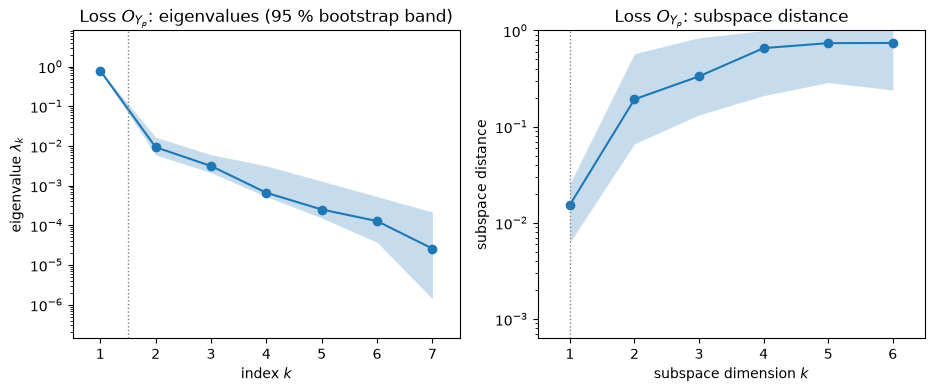

In [7]:
def eig_err_figure(s, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    ac.plotting.plot_eigenvalues(s, ax=a1)
    a1.set_title(f'{title}: eigenvalues (95 % bootstrap band)')
    ac.plotting.plot_subspace_errors(s, ax=a2)
    a2.set_title(f'{title}: subspace distance')
    plt.close(fig)
    d = ac.mean_distance(s)
    print(f'{title}: mean bootstrap subspace distance, k = 1..4:', np.array2string(d[:4], precision=4))
    return fig


fig = eig_err_figure(res['Yp'], 'Loss $O_{Y_p}$')
fig

The first eigenvalue is 84.5 times the second, and the one-dimensional subspace is the best determined, with mean bootstrap distance 0.0154 against 0.1927 for $k = 2$. The remaining eigenvalues decay smoothly with overlapping bands, so there is no second gap to exploit.

**First eigenvector.** The notebook's $w_1$ (Table 1 order) against the paper's Eq. 12 and the OLS direction (signed so the Kiel outer diameter component is positive).

w1 = [0.052 -0.002 -0.126 0.000 0.974 0.013 0.178]  (95 % bootstrap band half-widths [0.013 0.012 0.012 0.012 0.003 0.014 0.013])
|w1 . U_Y|/|U_Y| = 0.9996;  same with the hole-angle sign of the archive: 0.9695;  |w_ols . U_Y|/|U_Y| = 1.0000
against the authors' fitted U_Y: |w1 . U_Y| = 0.99965, |w_ols . U_Y| = 1.00000


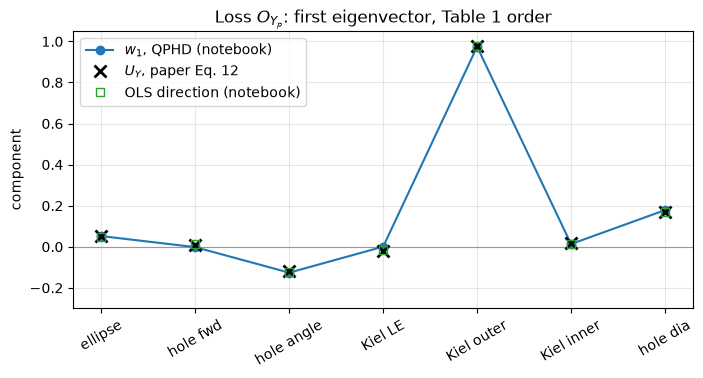

In [8]:
s = res['Yp']
w1 = s.eigenvectors[:, 0]
fig, ax = plt.subplots(figsize=(8, 3.6))
k = np.arange(m)
ax.axhline(0, color='0.6', lw=0.8)
ax.plot(k, w1, 'o-', label='$w_1$, QPHD (notebook)')
ax.plot(k, UY, 'kx', ms=9, mew=2, label='$U_Y$, paper Eq. 12')
ax.plot(k, unit(chk['Yp']['ols'].eigenvectors[:, 0]) * np.sign(chk['Yp']['ols'].eigenvectors[4, 0]), 's',
        mfc='none', color='C2', label='OLS direction (notebook)')
ax.set_xticks(k, short, rotation=30); ax.set_ylim(-0.3, 1.05); ax.set_ylabel('component')
ax.set_title('Loss $O_{Y_p}$: first eigenvector, Table 1 order'); ax.grid(True, alpha=0.3); ax.legend(loc='upper left')
plt.close(fig)
B = s.bootstrap_eigenvectors[:, :, 0]
print('w1 =', np.array2string(w1, formatter={'float_kind': lambda v: f'{v:.3f}'}), ' (95 % bootstrap band half-widths',
      np.array2string((np.percentile(B, 97.5, 0) - np.percentile(B, 2.5, 0)) / 2, precision=3) + ')')
print(f'|w1 . U_Y|/|U_Y| = {abs(w1 @ unit(UY)):.4f};  same with the hole-angle sign of the archive: '
      f'{abs(w1 @ unit(UY * np.array([1, 1, -1, 1, 1, 1, 1]))):.4f};  '
      f'|w_ols . U_Y|/|U_Y| = {abs(chk["Yp"]["ols"].eigenvectors[:, 0] @ unit(UY)):.4f}')
print(f"against the authors' fitted U_Y: |w1 . U_Y| = {abs(w1 @ unit(UY_authors)):.5f}, "
      f"|w_ols . U_Y| = {abs(chk['Yp']['ols'].eigenvectors[:, 0] @ unit(UY_authors)):.5f}")
fig

The loss direction is dominated by the Kiel outer diameter (0.974), with the bleed hole diameter (0.178) and the hole angle (−0.126) next, as in the paper's Eq. 12 (0.98, 0.17, −0.12); the cosine with Eq. 12 is 0.9996, and the OLS direction matches it to 1.0000. Against the authors' fitted $\mathbf U_Y$ the cosines are 0.99965 ($w_1$) and 1.00000 (OLS): the paper's linear ridge is the least-squares direction. With the archive's hole-angle sign the cosine would be 0.9695, and Fig. 7's baseline marker (next plot) also fits only the paper's sign. Bootstrap half-widths are at most 0.014 per component, so all seven components are well determined.

**Sufficient summary plot.** The loss against $y_1 = w_1^T\mathbf x$, with a linear fit and the baseline design (not one of the 128 runs) placed by its coordinates.

active variable range [-1.179, 1.125]; baseline y = -0.270; linear fit at baseline -0.2325 (std.) ~ 0.1089 % with Fig. 3(b) scale
1-D linear fit: slope 0.8863 per unit of y, R^2 0.9910


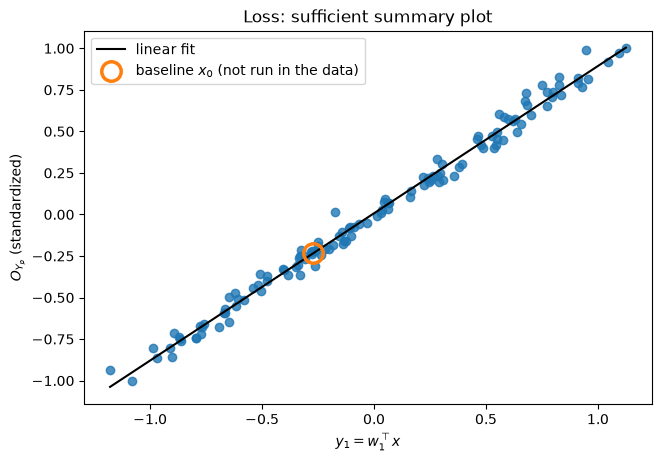

In [9]:
f = F[:, 0]
y = Z @ w1
c1 = np.polyfit(y, f, 1)
fig, ax = ac.plotting.plot_sufficient_summary(s, X=X, f=f, dims=1, qoi_label='$O_{Y_p}$ (standardized)', figsize=(6.5, 4.5))
yy = np.linspace(y.min(), y.max(), 50)
ax.plot(yy, np.polyval(c1, yy), 'k-', lw=1.5, label='linear fit')
yb = z0 @ w1
ax.plot(yb, np.polyval(c1, yb), 'o', ms=14, mfc='none', mec='C1', mew=2.5, label='baseline $x_0$ (not run in the data)')
ax.legend(loc='upper left'); ax.set_title('Loss: sufficient summary plot')
plt.close(fig)
# Approximate physical scale, read from the paper's Fig. 3(b) (see DATA.md); for comparison only
YP_A, YP_B = 0.118, 0.0393           # O_Yp (%) ~ YP_A + YP_B * Yp_std (figure reading, 3 significant figures)
print(f'active variable range [{y.min():.3f}, {y.max():.3f}]; baseline y = {yb:.3f}; '
      f'linear fit at baseline {np.polyval(c1, yb):+.4f} (std.) ~ {YP_A + YP_B * np.polyval(c1, yb):.4f} % with Fig. 3(b) scale')
r = f - np.polyval(c1, y)
print(f'1-D linear fit: slope {c1[0]:.4f} per unit of y, R^2 {1 - r @ r / ((f - f.mean()) @ (f - f.mean())):.4f}')
fig

The loss is a linear function of one active variable to within a small scatter: the line explains $R^2 = 0.9910$ with slope 0.8863 per unit of $y_1$, and the active variable spans $[-1.179, 1.125]$, close to the $[-1.155, 1.111]$ of the paper's Fig. 7 (computed from the authors' fitted $\mathbf U_Y$, printed above). The baseline lies at $y_1 = -0.270$ against −0.26 in Fig. 7 by pixel reading (−0.262 from the authors' $\mathbf U_Y$), and the line puts its loss at −0.2325 (standardized), about 0.109 % on the scale of Fig. 3(b), against the 0.110 % of Fig. 7's marker. Lower loss therefore means a smaller Kiel outer diameter, a smaller bleed hole and more bleed-hole angle, which the paper explains by bluff-body drag and the jet-in-crossflow at the bleed holes (Sec. 4.1, Fig. 8).

### Results: the recovery objective $O_{R_r}$

**Eigenvalues and subspace errors.**

Recovery $O_{R_r}$: mean bootstrap subspace distance, k = 1..4: [0.0967 0.2351 0.6698 0.7646]


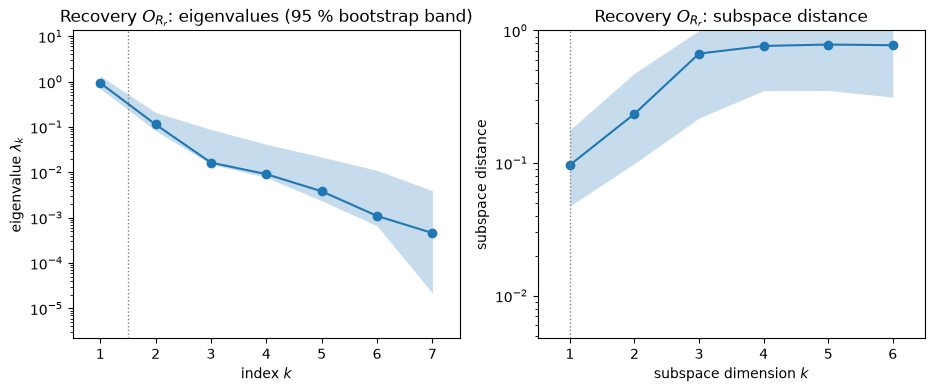

In [10]:
fig = eig_err_figure(res['ORr'], 'Recovery $O_{R_r}$')
fig

The spectrum has two gaps, 8.2 after the first eigenvalue and 6.94 after the second, and then a smooth decay. The mean bootstrap distance is 0.0967 for $k = 1$ and 0.2351 for $k = 2$, and jumps to 0.6698 for $k = 3$, so subspaces of dimension 1 and 2 are stable and dimension 3 is not.

**Eigenvectors.** $w_1$ and $w_2$ against the paper's $\mathbf U_R$: its first column is the vector of Fig. 11(a) ($\mathbf v_a = (1, 0)$), and its second column follows from Fig. 11(b), $\mathbf v_b\mathbf U_R$ with $\mathbf v_b = (0.15, -0.99)$. Fig. 11 was read by pixel measurement; the authors' fitted $\mathbf U_R$ shows the readings are within 0.0082 of the exact vectors (printed in the estimation cell). The third panel compares the direction $\mathbf v_b$ itself.

w1 = [ 0.312  0.05  -0.065  0.004 -0.006 -0.238  0.916] 
w2 = [ 0.094  0.094  0.217 -0.192  0.524 -0.76  -0.215]
w1 . U_R1 = 0.9971;  w2 . U_R2 = 0.9810;  (0.15 w1 - 0.99 w2) . Fig.11(b) = 0.9816
span(w1, w2) vs span(U_R): cosines of the principal angles 0.9972, 0.9810; subspace distance 0.194
span(w1, w2) vs the authors' fitted U_R: cosines of the principal angles 0.9974, 0.9816
with the archive hole-angle sign instead: cosines [0.9959 0.8802]


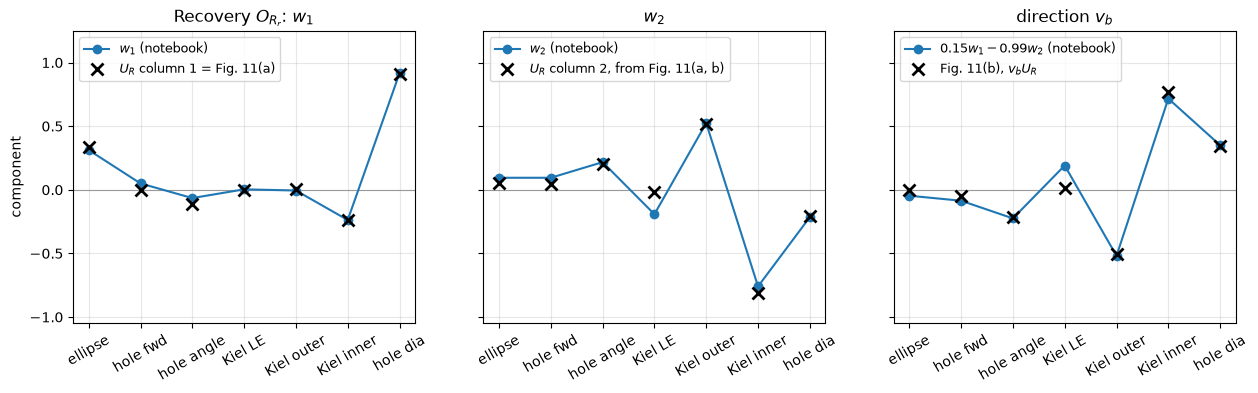

In [11]:
s = res['ORr']
W = s.eigenvectors
vb = np.array([0.15, -0.99])
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for i, (v, ref, lab) in enumerate([(W[:, 0], UR[:, 0], '$U_R$ column 1 = Fig. 11(a)'),
                                   (W[:, 1], UR[:, 1], '$U_R$ column 2, from Fig. 11(a, b)'),
                                   (W[:, :2] @ vb, fig11b, 'Fig. 11(b), $v_b U_R$')]):
    axs[i].axhline(0, color='0.6', lw=0.8)
    axs[i].plot(k, v, 'o-', label=['$w_1$', '$w_2$', '$0.15 w_1 - 0.99 w_2$'][i] + ' (notebook)')
    axs[i].plot(k, ref, 'kx', ms=9, mew=2, label=lab)
    axs[i].set_xticks(k, short, rotation=30); axs[i].grid(True, alpha=0.3); axs[i].legend(loc='upper left', fontsize=9)
axs[0].set_ylim(-1.05, 1.25); axs[0].set_ylabel('component')
axs[0].set_title('Recovery $O_{R_r}$: $w_1$'); axs[1].set_title('$w_2$'); axs[2].set_title('direction $v_b$')
plt.close(fig)
Q = np.linalg.qr(UR)[0]
cos = np.linalg.svd(W[:, :2].T @ Q)[1]
print('w1 =', np.array2string(W[:, 0], precision=3), '\nw2 =', np.array2string(W[:, 1], precision=3))
print(f'w1 . U_R1 = {W[:, 0] @ unit(UR[:, 0]):.4f};  w2 . U_R2 = {W[:, 1] @ unit(UR[:, 1]):.4f};  '
      f'(0.15 w1 - 0.99 w2) . Fig.11(b) = {unit(W[:, :2] @ vb) @ unit(fig11b):.4f}')
print(f'span(w1, w2) vs span(U_R): cosines of the principal angles {cos[0]:.4f}, {cos[1]:.4f}; '
      f'subspace distance {np.sqrt(1 - cos[1] ** 2):.3f}')
cosA = np.linalg.svd(W[:, :2].T @ np.linalg.qr(UR_authors)[0])[1]
print(f"span(w1, w2) vs the authors' fitted U_R: cosines of the principal angles {cosA[0]:.4f}, {cosA[1]:.4f}")
UR_archive = UR * np.array([1, 1, -1, 1, 1, 1, 1])[:, None]
print(f'with the archive hole-angle sign instead: cosines {np.array2string(np.linalg.svd(W[:, :2].T @ np.linalg.qr(UR_archive)[0])[1], precision=4)}')
fig

The first direction is mainly the bleed hole diameter (0.916) and the hole ellipse (0.312), with the Kiel inner diameter against them (−0.238): the vent-to-inlet area ratio, as the paper says (Sec. 4.2). It matches Fig. 11(a) with cosine 0.9971. The second direction, mainly Kiel inner (−0.76) against Kiel outer (0.524) diameter, is the shroud thickness; it matches the paper's second column with cosine 0.9810, the main difference being the Kiel leading-edge component (−0.192 here, about −0.02 in the paper). The two-dimensional subspaces agree with principal-angle cosines 0.9972 and 0.9810 (distance 0.194), and 0.9974 and 0.9816 against the authors' fitted $\mathbf U_R$; with the archive's hole-angle sign the second cosine would drop to 0.8802.

**Sufficient summary plots.** Left: the recovery objective against $y_1$ with a quadratic fit. Right: the two active variables coloured by the objective, with the baseline and the line through designs A, B and C of Fig. 10(a) ($u_{R,2} \approx 0.54$, read by eye).

active variables: y1 in [-1.299, 1.153], y2 in [-1.207, 1.572]; baseline (y1, y2) = (0.120, -0.641)
quadratic in y1 alone: minimum at y1 = 0.127; cubic in (y1, y2) along y2 = 0.54: minimum at y1 = 0.204
the 10 lowest-O_Rr designs: y1 in [-0.06, 0.55], y2 in [-1.21, -0.01]


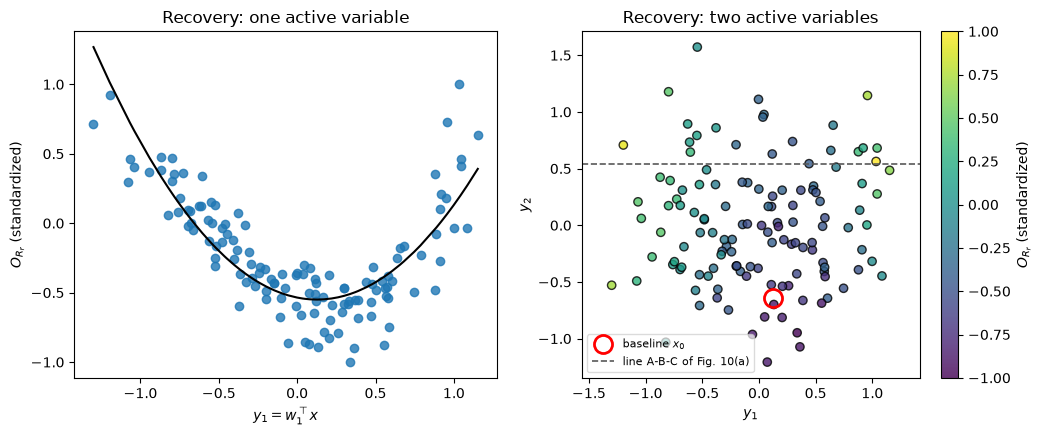

In [12]:
f = F[:, 1]
Y2 = Z @ W[:, :2]
yb2 = z0 @ W[:, :2]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(s, X=X, f=f, dims=1, qoi_label='$O_{R_r}$ (standardized)', ax=a1)
ac.plotting.plot_sufficient_summary(s, X=X, f=f, dims=2, qoi_label='$O_{R_r}$ (standardized)', ax=a2,
                                    scatter_kw={'cmap': 'viridis', 'edgecolors': 'k'})
a2.plot(*yb2, 'o', ms=13, mfc='none', mec='r', mew=2, label='baseline $x_0$')
a2.axhline(0.54, color='0.35', lw=1.2, ls='--', label='line A-B-C of Fig. 10(a)')
a2.legend(loc='lower left', fontsize=8, framealpha=0.7)
a1.set_title('Recovery: one active variable'); a2.set_title('Recovery: two active variables')
c2 = np.polyfit(Y2[:, 0], f, 2)
a1.plot(np.sort(Y2[:, 0]), np.polyval(c2, np.sort(Y2[:, 0])), 'k-', lw=1.5)
plt.close(fig)
cub = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(s, n=2), kind='poly', degree=3)
t = np.linspace(Y2[:, 0].min(), Y2[:, 0].max(), 1001)
gB = cub.evaluate(np.column_stack([t, np.full_like(t, 0.54)]))
print(f'active variables: y1 in [{Y2[:, 0].min():.3f}, {Y2[:, 0].max():.3f}], y2 in [{Y2[:, 1].min():.3f}, {Y2[:, 1].max():.3f}]; '
      f'baseline (y1, y2) = ({yb2[0]:.3f}, {yb2[1]:.3f})')
print(f'quadratic in y1 alone: minimum at y1 = {-c2[1] / (2 * c2[0]):.3f}; '
      f'cubic in (y1, y2) along y2 = 0.54: minimum at y1 = {t[np.argmin(gB)]:.3f}')
lowest = np.argsort(f)[:10]
print(f'the 10 lowest-O_Rr designs: y1 in [{Y2[lowest, 0].min():.2f}, {Y2[lowest, 0].max():.2f}], '
      f'y2 in [{Y2[lowest, 1].min():.2f}, {Y2[lowest, 1].max():.2f}]')
fig

The recovery objective is a valley in $y_1$: a quadratic in $y_1$ alone has its minimum at $y_1 = 0.127$, the optimum vent-to-inlet area ratio of the paper's Sec. 4.2. The second variable moves the valley floor: the 10 designs with the lowest $O_{R_r}$ all have $y_2 \le -0.01$ (and $y_1$ between −0.06 and 0.55), the region around design D at the bottom of Fig. 10(a). On the line A–B–C ($y_2 = 0.54$) the cubic surrogate below has its minimum at $y_1 = 0.204$, close to design B (about 0.15 in Fig. 10(a)). The active variables span $[-1.30, 1.15] \times [-1.21, 1.57]$, against roughly $[-1.4, 1.1] \times [-1.2, 1.5]$ in Fig. 10(a), and the baseline lies at $(0.12, -0.64)$ against $(0.13, -0.71)$.

### The recovery ratio at $M = 0.8$

Sec. 6 of the paper builds a two-dimensional subspace for $R_r$ at $M = 0.8$ (stored as `y3`) to study manufacturing tolerances. Since this output is almost perfectly anticorrelated with the recovery slope (−0.9977), its subspace should be nearly the same.

Rr(M=0.8): w1 = [ 0.317  0.05  -0.053 -0.003 -0.012 -0.237  0.915]
|w1(Rr08) . w1(O_Rr)| = 0.9999; span(w1, w2) of Rr(0.8) vs that of O_Rr: cosines 0.9999, 0.9972


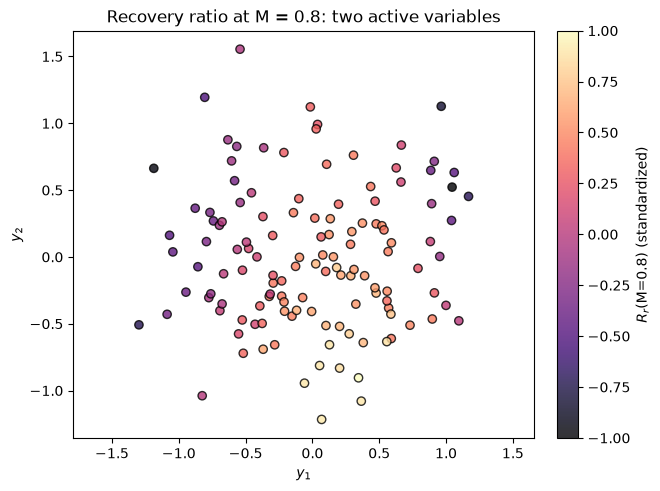

In [13]:
s3 = res['Rr08']
W3 = s3.eigenvectors
cos3 = np.linalg.svd(W3[:, :2].T @ W[:, :2])[1]
print(f'Rr(M=0.8): w1 =', np.array2string(W3[:, 0], precision=3))
print(f'|w1(Rr08) . w1(O_Rr)| = {abs(W3[:, 0] @ W[:, 0]):.4f}; span(w1, w2) of Rr(0.8) vs that of O_Rr: cosines {cos3[0]:.4f}, {cos3[1]:.4f}')
fig, ax = ac.plotting.plot_sufficient_summary(s3, X=X, f=F[:, 2], dims=2, qoi_label='$R_r$(M=0.8) (standardized)',
                                              figsize=(6.5, 4.8), scatter_kw={'cmap': 'magma', 'edgecolors': 'k'})
ax.set_title('Recovery ratio at M = 0.8: two active variables')
plt.close(fig)
fig

The first direction of $R_r(0.8)$ matches that of $O_{R_r}$ ($|w_1\cdot w_1| = 0.9999$), and the two-dimensional subspaces agree with principal-angle cosines 0.9999 and 0.9972; the eigenvalue ratios are 7.5 and 9.90. The plot is the mirror image of the recovery-slope plot: high $R_r(0.8)$ where the slope is small.

### Surrogates on the active variables

Polynomials of degree $k$ in $n$ active variables, with in-sample $R^2$ (the quantity of the paper's Fig. 6, for its own variable-projection ridges) and leave-one-out (LOO) $R^2$. The subspaces are held fixed at the quadratic estimates, so the LOO values do not include the error of estimating them. The plot shows the cubic in two variables for the recovery objective.

QoI    n degree     R^2  LOO R^2
Yp     1      1  0.9910   0.9907
Yp     1      2  0.9911   0.9907
Yp     1      3  0.9911   0.9904
Yp     2      2  0.9943   0.9938
Yp     2      3  0.9945   0.9935
ORr    1      1  0.0958   0.0519
ORr    1      2  0.7208   0.6968
ORr    1      3  0.7912   0.7716
ORr    2      2  0.8797   0.8606
ORr    2      3  0.9279   0.9091
Rr08   1      1  0.0815   0.0370
Rr08   1      2  0.7109   0.6870
Rr08   1      3  0.7732   0.7529
Rr08   2      2  0.8930   0.8762
Rr08   2      3  0.9360   0.9201
cubic in two variables on the authors' fitted U_R (in-sample R^2): O_Rr 0.9423, Rr(0.8) 0.9473


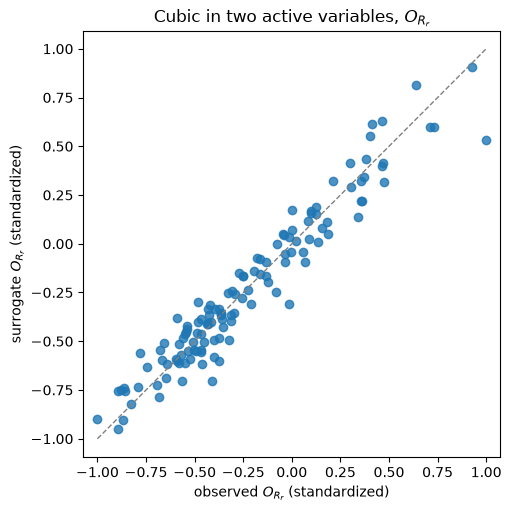

In [14]:
rows = []
for j, q in enumerate(qois):
    f = F[:, j]
    for n, deg in [(1, 1), (1, 2), (1, 3), (2, 2), (2, 3)]:
        sg = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(res[q], n=n), kind='poly', degree=deg)
        r2 = 1 - sg.residuals @ sg.residuals / ((f - f.mean()) @ (f - f.mean()))
        rows.append((q, n, deg, r2, sg.loo_r_squared))
        if (q, n, deg) == ('ORr', 2, 3):
            sur_ORr = sg
print(f"{'QoI':5s} {'n':>2s} {'degree':>6s} {'R^2':>7s} {'LOO R^2':>8s}")
for q, n, deg, r2, loo in rows:
    print(f'{q:5s} {n:2d} {deg:6d} {r2:7.4f} {loo:8.4f}')
R2 = {(q, n, d): (r2, loo) for q, n, d, r2, loo in rows}


def cubic_r2(Y, f):
    """in-sample R^2 of a full cubic in two variables"""
    A = np.column_stack([Y[:, 0] ** i * Y[:, 1] ** j for i in range(4) for j in range(4 - i)])
    r = f - A @ np.linalg.lstsq(A, f, rcond=None)[0]
    return 1 - r @ r / ((f - f.mean()) @ (f - f.mean()))


r2_authors = [cubic_r2(Z @ UR_authors, F[:, j]) for j in (1, 2)]
print(f"cubic in two variables on the authors' fitted U_R (in-sample R^2): O_Rr {r2_authors[0]:.4f}, Rr(0.8) {r2_authors[1]:.4f}")
fig, ax = ac.plotting.plot_surrogate_fit(sur_ORr, X=X, f=F[:, 1], qoi_label='$O_{R_r}$ (standardized)', figsize=(5, 5))
ax.set_title('Cubic in two active variables, $O_{R_r}$')
plt.close(fig)
fig

For the loss a straight line in one variable is enough (LOO $R^2 = 0.9907$); a second variable adds about 0.003. For the recovery objective one variable is not enough even with a cubic (LOO 0.7716), and the second variable raises the LOO $R^2$ of a cubic to 0.9091 (in-sample 0.9279, against the paper's 0.941 for its own two-dimensional cubic ridge). Variable projection chooses $\mathbf U$ to minimize the misfit of the cubic, so its $R^2$ should be at least ours for the same $(m, k)$; the difference of 0.013 is the price of using the quadratic's subspace. The same holds for $R_r(0.8)$: 0.9360 in-sample (LOO 0.9201) against the paper's 0.947. A cubic refitted on the authors' own $\mathbf U_R$ gives 0.9423 and 0.9473 against the paper's 0.941 and 0.947, which confirms that the gap comes from the subspace, not from the data.

### Comparison with the paper

Paper values are printed in the text or read from its figures: by pixel measurement (Fig. 7 baseline, Fig. 10(a) baseline, Fig. 11) or by eye (Figs. 6, 10(a) box and design B). Rows marked "authors'" are computed from the authors' fitted subspaces (`Yp_subspace.joblib`, `Rr_subspace.joblib`), including Fig. 7's active-variable range, which is the range of their $\mathbf U_Y^T\mathbf x$ over the 128 designs. The baseline $O_{Y_p}$ in the notebook column uses the Fig. 3(b) scale described above.

In [15]:
sY, sR = res['Yp'], res['ORr']
cosR = np.linalg.svd(sR.eigenvectors[:, :2].T @ np.linalg.qr(UR)[0])[1]
fmt = lambda v: '[' + ', '.join(f'{(0.0 if abs(x) < 0.005 else x):.2f}' for x in v) + ']'
wY, wR1, wR2 = sY.eigenvectors[:, 0], sR.eigenvectors[:, 0], sR.eigenvectors[:, 1]
table = [
    ('O_Yp: R^2 of linear ridge (m = 1, k = 1, Sec. 4)', '0.992', f'{chk["Yp"]["lin_r2"]:.4f} (least squares)'),
    ('O_Yp: R^2, m = 2, k = 2 (Fig. 6(a), eye)', '~0.995', f'{R2[("Yp", 2, 2)][0]:.4f}'),
    ('O_Yp: ridge direction, Table 1 order (Eq. 12)', fmt(UY), f'{fmt(wY)} (cosine {abs(wY @ unit(UY)):.4f})'),
    ("O_Yp: ridge direction, authors' fitted U_Y", fmt(UY_authors), f'{fmt(wY)} (cosine {abs(wY @ unit(UY_authors)):.4f})'),
    ("O_Yp: active-variable range (Fig. 7; authors' U_Y)", f'[{(Z @ UY_authors).min():.3f}, {(Z @ UY_authors).max():.3f}]',
     f'[{(Z @ wY).min():.3f}, {(Z @ wY).max():.3f}]'),
    ("O_Yp: baseline u_Y (Fig. 7 pixel; authors' U_Y)", f'-0.26; {z0 @ UY_authors:.3f}', f'{z0 @ wY:.3f}'),
    ('O_Yp: baseline O_Yp (Fig. 7, pixel)', '0.110 %', f'{YP_A + YP_B * np.polyval(c1, z0 @ wY):.3f} % (linear fit; Fig. 3(b) scale)'),
    ('O_Rr: R^2, m = 1, k = 1 (Fig. 6(b), eye)', '~0.36', f'{chk["ORr"]["lin_r2"]:.3f} (least squares)'),
    ('O_Rr: R^2, m = 1, k = 2 / k = 3 (Fig. 6(b), eye)', '~0.72 / ~0.81', f'{R2[("ORr", 1, 2)][0]:.3f} / {R2[("ORr", 1, 3)][0]:.3f}'),
    ('O_Rr: R^2, m = 2, k = 2 (Fig. 6(b), eye)', '~0.88', f'{R2[("ORr", 2, 2)][0]:.3f}'),
    ('O_Rr: R^2, m = 2, k = 3 (Sec. 4)', '0.941', f'{R2[("ORr", 2, 3)][0]:.3f} (LOO {R2[("ORr", 2, 3)][1]:.3f})'),
    ('O_Rr: u_R1 = v_a U_R (Fig. 11(a), pixel)', fmt(fig11a), f'{fmt(wR1)} (cosine {wR1 @ unit(UR[:, 0]):.4f})'),
    ('O_Rr: u_R2 (from Fig. 11(a, b))', fmt(UR[:, 1]), f'{fmt(wR2)} (cosine {wR2 @ unit(UR[:, 1]):.4f})'),
    ('O_Rr: principal-angle cosines, 2-D subspaces', 'not reported', f'{cosR[0]:.4f}, {cosR[1]:.4f}'),
    ("O_Rr: principal-angle cosines vs authors' fitted U_R", 'not reported', f'{cosA[0]:.4f}, {cosA[1]:.4f}'),
    ("O_Rr: R^2, m = 2, k = 3, cubic refitted on authors' U_R", '0.941', f'{r2_authors[0]:.4f}'),
    ('O_Rr: active-variable box (Fig. 10(a), eye)', '[-1.4, 1.1] x [-1.2, 1.5]',
     f'[{Y2[:, 0].min():.2f}, {Y2[:, 0].max():.2f}] x [{Y2[:, 1].min():.2f}, {Y2[:, 1].max():.2f}]'),
    ('O_Rr: baseline (u_R1, u_R2) (Fig. 10(a), pixel)', '(0.13, -0.71)', f'({yb2[0]:.2f}, {yb2[1]:.2f})'),
    ('O_Rr: design B, minimum on line A-C (Fig. 10(a))', 'u_R1 ~ 0.15', f'{t[np.argmin(gB)]:.2f} (cubic, y2 = 0.54)'),
    ('O_Rr: largest value (Sec. 2)', '0.0079', 'standardized to 1 (Fig. 3(b) scale: 0.0079)'),
    ('Rr(0.8): R^2, m = 2, k = 3 (Sec. 6)', '0.947', f'{R2[("Rr08", 2, 3)][0]:.3f} (LOO {R2[("Rr08", 2, 3)][1]:.3f})'),
    ('eigenvalue ratios lam1/lam2 (O_Yp, O_Rr)', 'not reported', f'{sY.eigenvalues[0] / sY.eigenvalues[1]:.1f}, {sR.eigenvalues[0] / sR.eigenvalues[1]:.2f}'),
]
w0 = max(len(t[0]) for t in table); w1_ = max(len(t[1]) for t in table)
print(f"{'quantity':{w0}s}  {'paper':{w1_}s}  notebook")
for a, b, c in table:
    print(f'{a:{w0}s}  {b:{w1_}s}  {c}')

quantity                                                 paper                                          notebook
O_Yp: R^2 of linear ridge (m = 1, k = 1, Sec. 4)         0.992                                          0.9917 (least squares)
O_Yp: R^2, m = 2, k = 2 (Fig. 6(a), eye)                 ~0.995                                         0.9943
O_Yp: ridge direction, Table 1 order (Eq. 12)            [0.05, 0.01, -0.12, -0.02, 0.98, 0.02, 0.17]   [0.05, 0.00, -0.13, 0.00, 0.97, 0.01, 0.18] (cosine 0.9996)
O_Yp: ridge direction, authors' fitted U_Y               [0.05, 0.01, -0.12, -0.02, 0.98, 0.02, 0.17]   [0.05, 0.00, -0.13, 0.00, 0.97, 0.01, 0.18] (cosine 0.9997)
O_Yp: active-variable range (Fig. 7; authors' U_Y)       [-1.155, 1.111]                                [-1.179, 1.125]
O_Yp: baseline u_Y (Fig. 7 pixel; authors' U_Y)          -0.26; -0.262                                  -0.270
O_Yp: baseline O_Yp (Fig. 7, pixel)                      0.110 %                          

The paper's structural results are reproduced from the archive: the linear loss ridge and its weights, the two-dimensional recovery subspace and its two directions, the valley along the vent-to-inlet direction with its minimum near design B, and the $R^2$ values of Fig. 6 for the low-order fits (0.3575, 0.721, 0.791 and 0.880 against about 0.36, 0.72, 0.81 and 0.88). The reproduction needs the archive's columns reversed and its hole-angle column negated, as the authors' companion code does; the authors' fitted subspaces confirm this map. The two-variable cubic $R^2$ values are 0.013 and 0.011 below the paper's because the subspaces here come from the global quadratic rather than from variable projection: refitted on the authors' $\mathbf U_R$, the cubic gives 0.9423 and 0.9473. Absolute values of the objectives are not in the archive, and the eigenvalues have no counterpart in the paper.

### References

[1] A. D. Scillitoe, B. Ubald, P. Seshadri, and S. Shahpar. [Design space exploration of stagnation temperature probes via dimension reduction](https://doi.org/10.1115/GT2020-16277). *Proceedings of ASME Turbo Expo 2020: Turbomachinery Technical Conference and Exposition*, Volume 2C: Turbomachinery, V02CT35A057, 2020. ASME Paper GT2020-16277. Data: [equadratures/data-sets](https://github.com/equadratures/data-sets), `probes`; code: [ascillitoe/probe-subspaces](https://github.com/ascillitoe/probe-subspaces).

[2] J. M. Hokanson and P. G. Constantine. [Data-driven polynomial ridge approximation using variable projection](https://doi.org/10.1137/17M1117690). *SIAM Journal on Scientific Computing*, 40(3):A1566–A1589, 2018.

[3] P. Seshadri and G. Parks. [Effective-Quadratures (EQ): polynomials for computational engineering studies](https://doi.org/10.21105/joss.00166). *Journal of Open Source Software*, 2(11):166, 2017.

[4] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[5] K.-C. Li. [On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma](https://doi.org/10.1080/01621459.1992.10476258). *Journal of the American Statistical Association*, 87(420):1025–1039, 1992.

[R1]: https://doi.org/10.1115/GT2020-16277
[R2]: https://doi.org/10.1137/17M1117690
[R3]: https://doi.org/10.21105/joss.00166
[R4]: https://doi.org/10.1137/1.9781611973860
[R5]: https://doi.org/10.1080/01621459.1992.10476258

### Acknowledgments

From [[1]][R1] (p. 10): "This work was supported by the Lloyd's Register Foundation-Alan Turing Institute Strategic Priorities Fund (EPSRC grant: EP/T001569/1) and an EPSRC/Rolls-Royce ICASE Award (EPSRC grant: EP/N509103/1)." The paper's ridge approximations were computed with Effective Quadratures [[3]][R3].

In [16]:
print(f'notebook run time: {time.perf_counter() - t_start:.1f} s')

notebook run time: 25.3 s
